In [7]:
import pandas as pd
import geopandas as gpd
import os
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pathlib import Path
import gc
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

os.chdir('C:\\Users\\hamod4691\\Code\\arctic-benthic-biodiversity')

# Spatial join with LME

In [2]:
# Spatial join: add LME name to all_merged_geo using intersects

all_merged_geo = pd.read_parquet("Gear/merged_all_gear.parquet").copy()
all_merged_geo["_row_id"] = np.arange(len(all_merged_geo))

# Build valid point geometries
lon = pd.to_numeric(all_merged_geo["decimalLongitudeStart"], errors="coerce")
lat = pd.to_numeric(all_merged_geo["decimalLatitudeStart"], errors="coerce")
valid = lon.between(-180, 180) & lat.between(-90, 90)

pts = gpd.GeoDataFrame(
    all_merged_geo.loc[valid, ["_row_id"]].copy(),
    geometry=gpd.points_from_xy(lon[valid], lat[valid]),
    crs="EPSG:4326",
)

# Load LME polygons
lme_path = "LME_boundaries_2014/LME_2013_polygon_projected.shp"
lme_gdf = gpd.read_file(lme_path).to_crs("EPSG:4326")

# Find LME name column (expects "LME", fallback to first column containing "lme")
if "LME" in lme_gdf.columns:
    lme_col = "LME"
else:
    candidates = [c for c in lme_gdf.columns if "lme" in c.lower()]
    if not candidates:
        raise KeyError("No LME name column found in shapefile.")
    lme_col = candidates[0]

# Spatial join with intersects
joined = gpd.sjoin(
    pts,
    lme_gdf[[lme_col, "geometry"]],
    how="left",
    predicate="intersects"
).drop(columns=["index_right"], errors="ignore")

# If a point intersects multiple polygons, keep first non-null LME
lme_map = (
    joined.groupby("_row_id")[lme_col]
    .agg(lambda s: next((v for v in s if pd.notna(v) and str(v).strip() != ""), np.nan))
)

# Write result back into the existing largeMarineEcosystem column
all_merged_geo["largeMarineEcosystem"] = all_merged_geo["_row_id"].map(lme_map)

# Check for rows that could not be matched to any LME
unmatched_mask = all_merged_geo["largeMarineEcosystem"].isna()
unmatched_count = int(unmatched_mask.sum())
print("Unmatched rows:", unmatched_count)
if unmatched_count > 0:
    print(all_merged_geo.loc[unmatched_mask, ["decimalLatitudeStart", "decimalLongitudeStart"]].head())

all_merged_geo = all_merged_geo.drop(columns="_row_id")

# Save
all_merged_geo.to_parquet("LME_boundaries_2014/merged_all_lme.parquet", index=False)

print("Saved with largeMarineEcosystem column:", all_merged_geo["largeMarineEcosystem"].notna().sum(), "rows matched")
all_merged_geo[["decimalLatitudeStart", "decimalLongitudeStart", "largeMarineEcosystem"]].head()

Unmatched rows: 380
       decimalLatitudeStart  decimalLongitudeStart
7254              72.000000             -40.000000
8529              79.083000             -26.683001
24619             75.717003             -34.367001
57725             71.983299             -38.000000
61740             75.031670             -35.685001
Saved with largeMarineEcosystem column: 3750206 rows matched


,decimalLatitudeStart,decimalLongitudeStart,largeMarineEcosystem
0,70.001883,-126.254916,Beaufort Sea LME
1,63.718060,-68.518610,Baffin Bay LME
2,53.292600,-169.778670,Aleutian Islands LME
3,55.740002,-162.823334,East Bering Sea LME
4,72.351167,-119.073333,Beaufort Sea LME


## Check unmatched rows

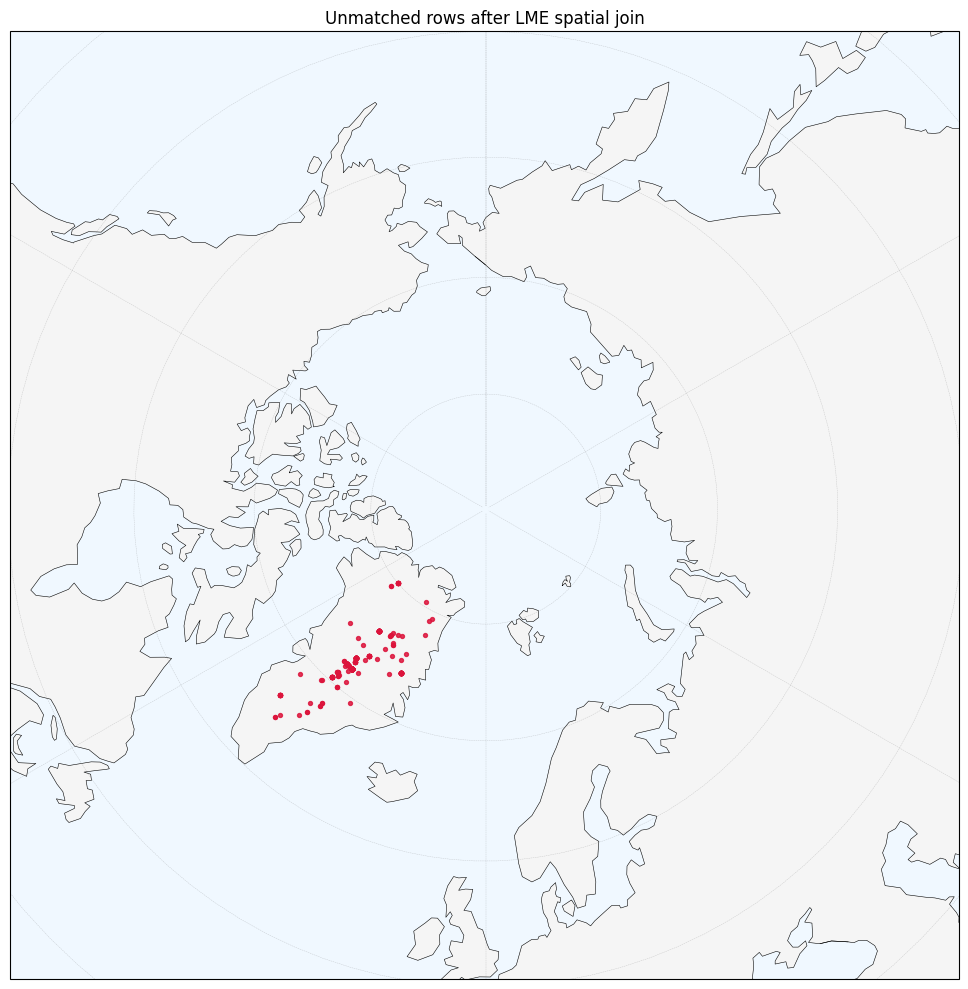

In [3]:
# Map unmatched rows after the spatial join
# Load the joined output so this cell is independent of notebook state
df_unmatched = pd.read_parquet("LME_boundaries_2014/merged_all_lme.parquet").copy()

df_unmatched["decimalLatitudeStart"] = pd.to_numeric(df_unmatched["decimalLatitudeStart"], errors="coerce")
df_unmatched["decimalLongitudeStart"] = pd.to_numeric(df_unmatched["decimalLongitudeStart"], errors="coerce")

# Keep only rows with valid coordinates and missing LME assignment
unmatched = df_unmatched[
    df_unmatched["largeMarineEcosystem"].isna()
    & df_unmatched["decimalLatitudeStart"].between(-90, 90)
    & df_unmatched["decimalLongitudeStart"].between(-180, 180)
].copy()

if unmatched.empty:
    print("No unmatched rows to plot.")
else:
    # Focus on the Arctic region so the unmatched points are easier to inspect
    unmatched = unmatched[unmatched["decimalLatitudeStart"] >= 50].copy()

    if unmatched.empty:
        print("No unmatched rows remain after limiting the map to lat >= 50.")
    else:
        fig = plt.figure(figsize=(10, 10))
        ax = plt.axes(projection=ccrs.NorthPolarStereo())
        ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
        ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
        ax.coastlines(resolution="110m", linewidth=0.4, color="black", zorder=1)
        ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

        ax.scatter(
            unmatched["decimalLongitudeStart"].values,
            unmatched["decimalLatitudeStart"].values,
            s=8,
            alpha=0.85,
            color="crimson",
            transform=ccrs.PlateCarree(),
            zorder=2,
        )

        ax.set_title("Unmatched rows after LME spatial join", fontsize=12)
        plt.tight_layout()
        plt.show()


## Remove unmatched rows

In [ ]:
# Remove unmatched rows and overwrite the parquet without loading the full file into memory twice.
parquet_path = Path("LME_boundaries_2014/merged_all_lme.parquet")
temp_path = parquet_path.with_suffix(".tmp.parquet")

removed_count = 0
remaining_rows = 0

parquet_file = pq.ParquetFile(parquet_path)
with pq.ParquetWriter(temp_path, parquet_file.schema_arrow) as writer:
    for batch in parquet_file.iter_batches(batch_size=250000):
        table = pa.Table.from_batches([batch])
        lme_values = table["largeMarineEcosystem"]
        keep_mask = pc.and_(
            pc.invert(pc.is_null(lme_values)),
            pc.not_equal(pc.utf8_trim_whitespace(pc.cast(lme_values, pa.string())), ""),
        )
        filtered = table.filter(keep_mask)
        removed_count += table.num_rows - filtered.num_rows
        remaining_rows += filtered.num_rows
        if filtered.num_rows:
            writer.write_table(filtered)

del parquet_file
gc.collect()

if removed_count == 0:
    if temp_path.exists():
        temp_path.unlink()
    print("No unmatched rows found; parquet was left unchanged.")
else:
    os.replace(temp_path, parquet_path)
    print(f"Removed {removed_count} unmatched rows and overwrote {parquet_path.name}")
    print("Remaining rows:", remaining_rows)

Removed 380 unmatched rows and overwrote merged_all_lme.parquet
Remaining rows: 3750206


## Visual validation of spatial join

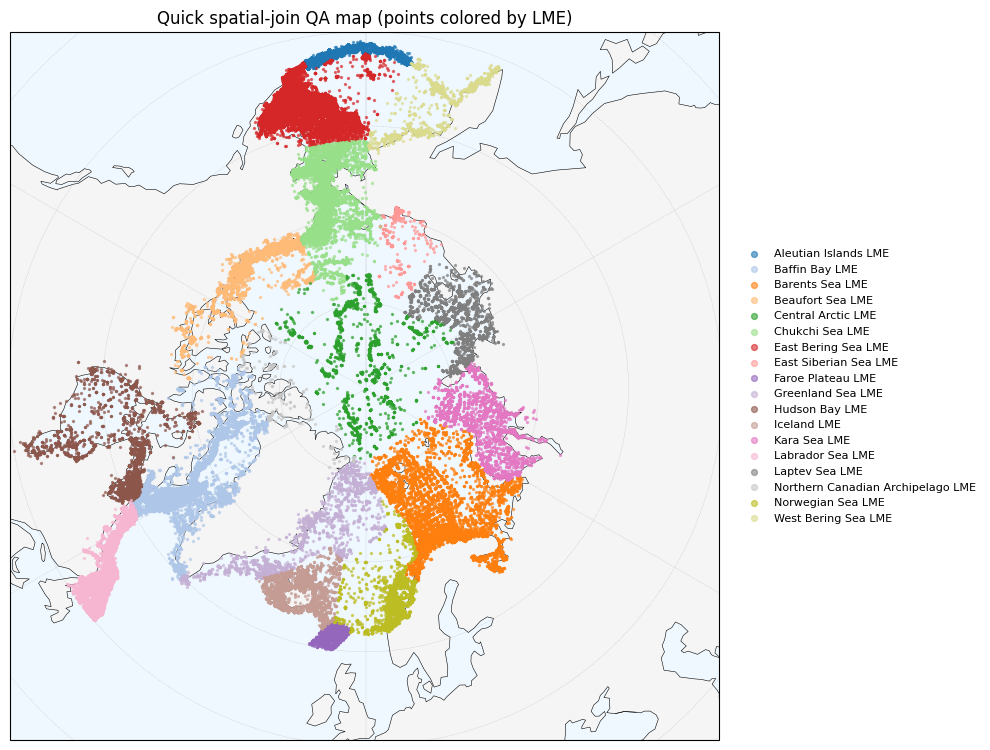

In [8]:
# Quick QA map for spatial join accuracy (LME-colored points, polar projection)

# Load from saved parquet to avoid kernel state mismatch
df_plot = pd.read_parquet("LME_boundaries_2014/merged_all_lme.parquet").copy()
if "largeMarineEcosystem" not in df_plot.columns:
    raise KeyError("Column 'largeMarineEcosystem' not found in merged_all_lme.parquet")

# Keep only rows with usable coordinates
df_plot["decimalLatitudeStart"] = pd.to_numeric(df_plot["decimalLatitudeStart"], errors="coerce")
df_plot["decimalLongitudeStart"] = pd.to_numeric(df_plot["decimalLongitudeStart"], errors="coerce")

df_plot = df_plot[
    df_plot["decimalLatitudeStart"].between(-90, 90)
    & df_plot["decimalLongitudeStart"].between(-180, 180)
].copy()

# Focus on Arctic extent and reduce overplotting
df_plot = df_plot[df_plot["decimalLatitudeStart"] >= 50].copy()
df_plot["largeMarineEcosystem"] = df_plot["largeMarineEcosystem"].astype("string").fillna("Unassigned").str.strip().replace("", "Unassigned")

# Optional speed-up: unique station-LME combos only
df_plot = df_plot.drop_duplicates(subset=["decimalLatitudeStart", "decimalLongitudeStart", "largeMarineEcosystem"])

if df_plot.empty:
    raise ValueError("No Arctic points available after filtering (lat >= 50 and valid lon/lat).")

# Optional speed-up: cap points per LME for plotting
max_per_lme = 15000
df_plot = df_plot.groupby("largeMarineEcosystem", group_keys=False).head(max_per_lme).copy()

# Color map
lmes = sorted(df_plot["largeMarineEcosystem"].dropna().unique().tolist())
palette = sns.color_palette("tab20", n_colors=len(lmes))
lme_colors = dict(zip(lmes, palette))

# Plot
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=ccrs.NorthPolarStereo())
ax.set_extent([-180, 180, 50, 90], crs=ccrs.PlateCarree())
ax.add_feature(cfeature.LAND, facecolor="whitesmoke", zorder=0)
ax.add_feature(cfeature.OCEAN, facecolor="aliceblue", zorder=0)
ax.coastlines(resolution="110m", linewidth=0.4, color="black", zorder=1)
ax.gridlines(draw_labels=False, linewidth=0.3, color="gray", alpha=0.4, linestyle="--")

for lme in lmes:
    sub = df_plot[df_plot["largeMarineEcosystem"] == lme]
    ax.scatter(
        sub["decimalLongitudeStart"].values,
        sub["decimalLatitudeStart"].values,
        s=2,
        alpha=0.6,
        color=lme_colors[lme],
        transform=ccrs.PlateCarree(),
        label=lme,
        zorder=2,
    )

ax.set_title("Quick spatial-join QA map (points colored by LME)", fontsize=12)
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=8,
    markerscale=3,
    ncol=1,
)

plt.tight_layout()
plt.show()

# Remove stations on land

In [9]:
# Load the parquet file and extract unique station-level information
df_stations = pd.read_parquet("LME_boundaries_2014/merged_all_lme.parquet")

# Select unique combinations of coordinates, year, datasetTitle, datasetKey, and sourceDatabase
unique_stations = df_stations[
    ["decimalLatitudeStart", "decimalLongitudeStart", "year", "datasetTitle", "datasetKey", "sourceDatabase"]
].drop_duplicates()

# Save to CSV
unique_stations.to_csv("LME_boundaries_2014/unique_stations.csv", index=False)

print(f"Saved {len(unique_stations)} unique station records to unique_stations.csv")

Saved 221788 unique station records to unique_stations.csv


Manually go through in ArcGIS

In [10]:
# Filter merged_all_lme.parquet using coordinate pairs marked with "x" in unique_stations_manual.csv

filter_csv = "LME_boundaries_2014/unique_stations_manual.csv"
parquet_path = "LME_boundaries_2014/merged_all_lme.parquet"

# Load filter table and identify rows marked for removal
df_filter = pd.read_csv(filter_csv)
if "remove" not in df_filter.columns:
    raise KeyError("Column 'remove' not found in unique_stations_manual.csv")

remove_mask = df_filter["remove"].astype("string").str.strip().str.lower().eq("x")
coords_to_remove = (
    df_filter.loc[remove_mask, ["decimalLatitudeStart", "decimalLongitudeStart"]]
    .assign(
        decimalLatitudeStart=lambda d: pd.to_numeric(d["decimalLatitudeStart"], errors="coerce"),
        decimalLongitudeStart=lambda d: pd.to_numeric(d["decimalLongitudeStart"], errors="coerce"),
    )
    .dropna()
    .drop_duplicates()
)

remove_set = set(zip(coords_to_remove["decimalLatitudeStart"], coords_to_remove["decimalLongitudeStart"]))

# Load parquet and filter matching coordinate pairs
df_all = pd.read_parquet(parquet_path).copy()
before_count = len(df_all)

df_all["decimalLatitudeStart"] = pd.to_numeric(df_all["decimalLatitudeStart"], errors="coerce")
df_all["decimalLongitudeStart"] = pd.to_numeric(df_all["decimalLongitudeStart"], errors="coerce")

keep_mask = ~df_all.apply(
    lambda r: (r["decimalLatitudeStart"], r["decimalLongitudeStart"]) in remove_set,
    axis=1,
)

df_all_filtered = df_all.loc[keep_mask].copy()
after_count = len(df_all_filtered)

# Save back to the same parquet file
df_all_filtered.to_parquet(parquet_path, index=False)

print(f"Records before: {before_count}")
print(f"Records after:  {after_count}")
print(f"Removed:        {before_count - after_count}")

Records before: 3750206
Records after:  3736407
Removed:        13799
